# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Intifada Afkar Lazain Muhammad | 5054251029 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

INC = "Annual Income (k$)"
SPD = "Spending Score (1-100)"


def plot_clusters(ax, data, labels, title):
    """Scatter plot berwarna per cluster; noise (-1) ditampilkan sebagai x hitam."""
    labels = np.asarray(labels)
    palette = sns.color_palette("tab10", 10)
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(data.loc[m, INC], data.loc[m, SPD], c="black", marker="x", s=40, label="Noise")
        else:
            ax.scatter(data.loc[m, INC], data.loc[m, SPD], color=palette[lab % 10], s=35, alpha=0.8, label=f"Cluster {lab}")
    ax.set_title(title)
    ax.set_xlabel(INC)
    ax.set_ylabel(SPD)
    ax.legend(fontsize=8)

In [ ]:

df = pd.read_csv("Mall_Customers.csv")


display(df.head())
print("Jumlah baris, kolom:", df.shape)
print("\nTipe data:")
print(df.dtypes)
print("\nStatistik deskriptif:")
display(df.describe().T)
print("Missing value per kolom:")
print(df.isna().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Jumlah baris, kolom: (200, 5)

Tipe data:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0


Missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0


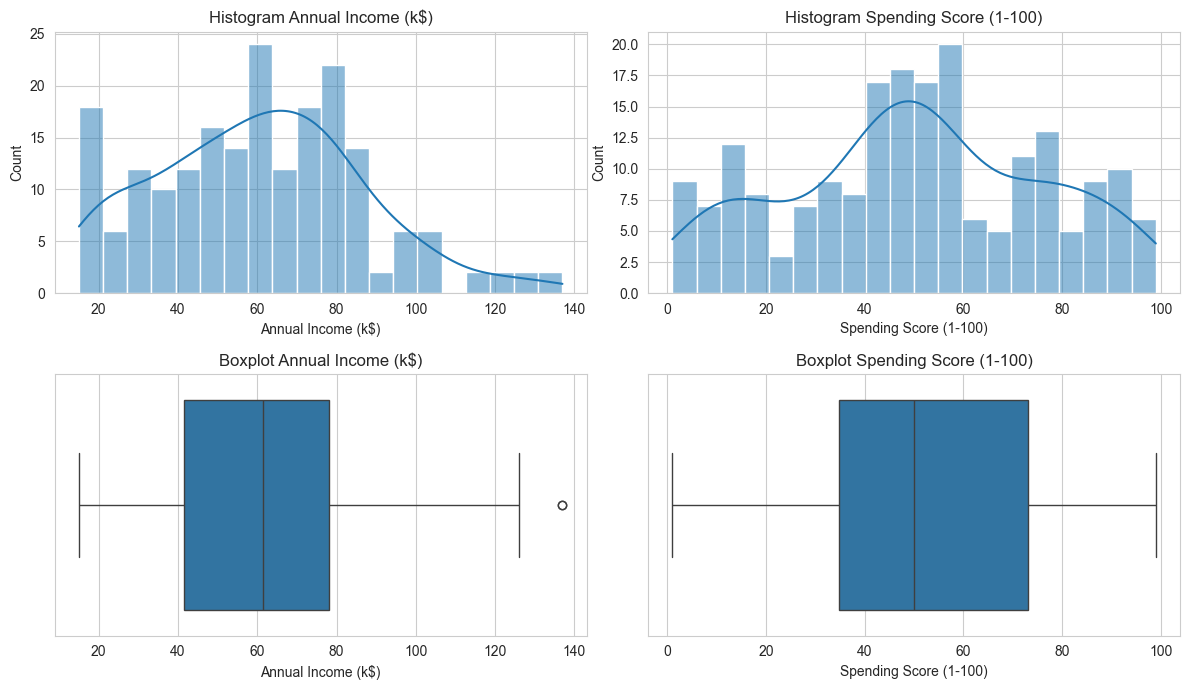

,min,max,mean,median,std,skew
Annual Income (k$),15.0,137.0,60.56,61.5,26.26,0.32
Spending Score (1-100),1.0,99.0,50.20,50.0,25.82,-0.05


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, col in enumerate([INC, SPD]):
    sns.histplot(df[col], bins=20, kde=True, ax=axes[0, j])
    axes[0, j].set_title(f"Histogram {col}")
    sns.boxplot(x=df[col], ax=axes[1, j])
    axes[1, j].set_title(f"Boxplot {col}")
plt.tight_layout()
plt.show()

display(df[[INC, SPD]].agg(["min", "max", "mean", "median", "std", "skew"]).T.round(2))

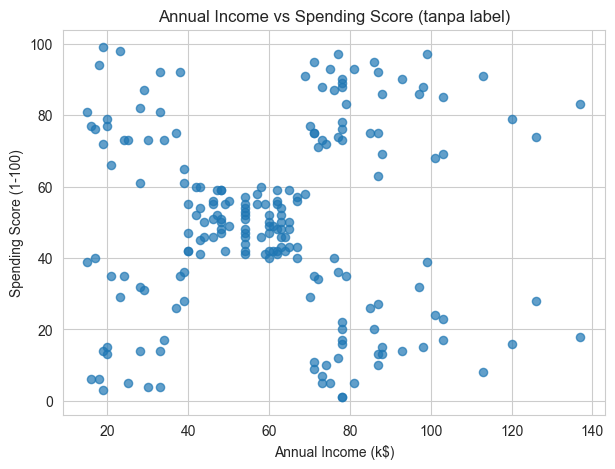

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(df[INC], df[SPD], s=35, alpha=0.7)
plt.xlabel(INC)
plt.ylabel(SPD)
plt.title("Annual Income vs Spending Score (tanpa label)")
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?


---

**Jawaban:**

- Dataset berisi 200 pelanggan. Hasil pemeriksaan pada output di atas menunjukkan tidak ada missing value dan tidak ada baris duplikat, sehingga tidak diperlukan penghapusan atau imputasi data.
- Annual Income berkisar dari sekitar 15 sampai 137 k$ dengan distribusi agak menumpuk di kiri, sedangkan Spending Score berkisar dari 1 sampai 99 dengan distribusi yang lebih simetris di sekitar nilai tengahnya. Hanya ada sedikit titik di ujung atas pendapatan yang terlihat sebagai outlier pada boxplot, dan nilainya masih wajar sehingga tidak dibuang.
- Pada scatter plot terlihat beberapa kelompok pelanggan yang cukup terpisah: kelompok di tengah (pendapatan dan spending sedang) yang paling padat, serta kelompok di sudut-sudut plot (pendapatan rendah dengan spending rendah, pendapatan rendah dengan spending tinggi, pendapatan tinggi dengan spending rendah, dan pendapatan tinggi dengan spending tinggi). Pola ini menunjukkan data layak untuk dikelompokkan menjadi sekitar lima cluster.

# 2. Preprocessing

In [5]:
print("Missing value:", int(df.isna().sum().sum()))
n_dup = int(df.duplicated().sum())
if n_dup > 0:
    df = df.drop_duplicates().reset_index(drop=True)
print("Baris duplikat dihapus:", n_dup, "| jumlah baris sekarang:", len(df))

# CustomerID (dan Gender) tidak dipakai sebagai fitur clustering
X = df[[INC, SPD]].copy()
display(X.head())
print("Bentuk X:", X.shape)

Missing value: 0
Baris duplikat dihapus: 0 | jumlah baris sekarang: 200


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


Bentuk X: (200, 2)


In [6]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

display(X_scaled.head())
display(X_scaled.describe().T.round(3))

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,count,mean,std,min,25%,50%,75%,max
Annual Income (k$),200.0,-0.0,1.003,-1.739,-0.728,0.036,0.666,2.918
Spending Score (1-100),200.0,-0.0,1.003,-1.910,-0.600,-0.008,0.885,1.894


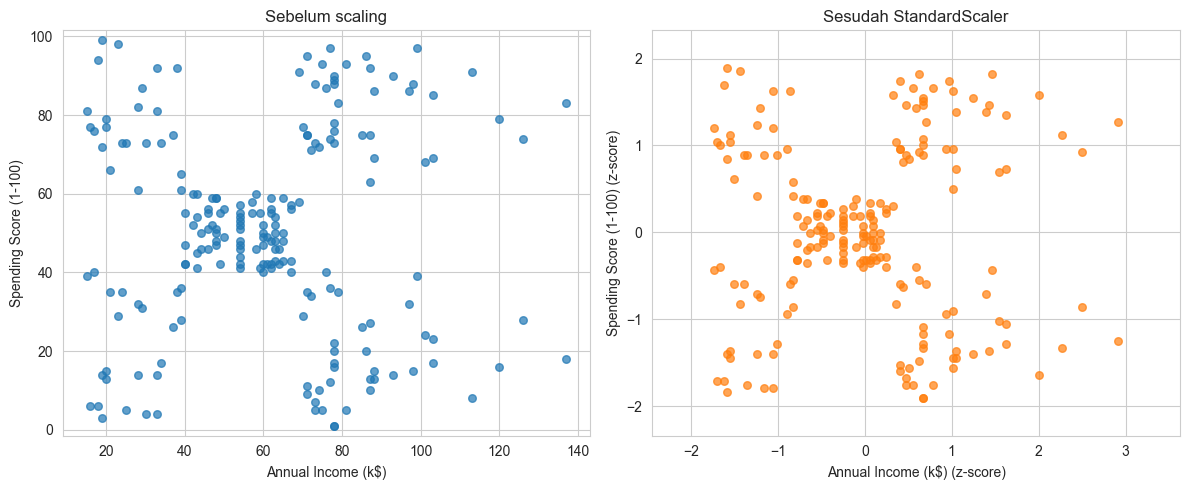

Rentang sebelum scaling:
Annual Income (k$)        122
Spending Score (1-100)     98
dtype: int64

Std sesudah scaling:
Annual Income (k$)        1.003
Spending Score (1-100)    1.003
dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X[INC], X[SPD], s=30, alpha=0.7)
axes[0].set_title("Sebelum scaling")
axes[0].set_xlabel(INC); axes[0].set_ylabel(SPD)
axes[0].set_aspect("equal", adjustable="datalim")

axes[1].scatter(X_scaled[INC], X_scaled[SPD], s=30, alpha=0.7, color="tab:orange")
axes[1].set_title("Sesudah StandardScaler")
axes[1].set_xlabel(INC + " (z-score)"); axes[1].set_ylabel(SPD + " (z-score)")
axes[1].set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

print("Rentang sebelum scaling:")
print((X.max() - X.min()).round(1))
print("\nStd sesudah scaling:")
print(X_scaled.std().round(3))

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.


---

Alasan pemilihan fitur: Annual Income menggambarkan daya beli pelanggan, sedangkan Spending Score menggambarkan perilaku belanjanya. Kombinasi keduanya paling relevan untuk segmentasi pelanggan, dan dua dimensi memudahkan visualisasi hasil cluster secara langsung. CustomerID tidak digunakan karena hanya nomor identitas tanpa makna perilaku; jika dimasukkan, urutan nomor akan ikut memengaruhi jarak antar titik tanpa alasan yang masuk akal.

Mengapa scaling penting: DBSCAN dan BIRCH bekerja berdasarkan jarak (eps dan threshold adalah ukuran jarak), dan GMM menghitung kovarians antar fitur. Jika skala fitur berbeda, fitur dengan rentang lebih besar akan mendominasi jarak. Pada data ini kedua fitur sebenarnya memiliki rentang yang mirip, tetapi StandardScaler tetap digunakan agar kedua fitur berkontribusi setara, nilai eps dan threshold memiliki arti yang konsisten (dalam satuan simpangan baku), dan prosedur yang sama tetap valid bila fitur lain seperti usia ditambahkan nanti.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
db = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = db.fit_predict(X_scaled)
print("Label unik DBSCAN:", sorted(set(labels_dbscan)))

Label unik DBSCAN: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [9]:
counts_db = pd.Series(labels_dbscan).value_counts().sort_index()
display(counts_db.to_frame("jumlah_anggota").rename_axis("label"))
n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_db = int((labels_dbscan == -1).sum())
print("Jumlah cluster (tanpa noise):", n_clusters_db)
print("Jumlah noise:", n_noise_db, f"({n_noise_db / len(labels_dbscan) * 100:.1f}%)")

,jumlah_anggota
label,
-1,35
0,12
1,5
2,7
3,88
4,30
5,14
6,9


Jumlah cluster (tanpa noise): 7
Jumlah noise: 35 (17.5%)


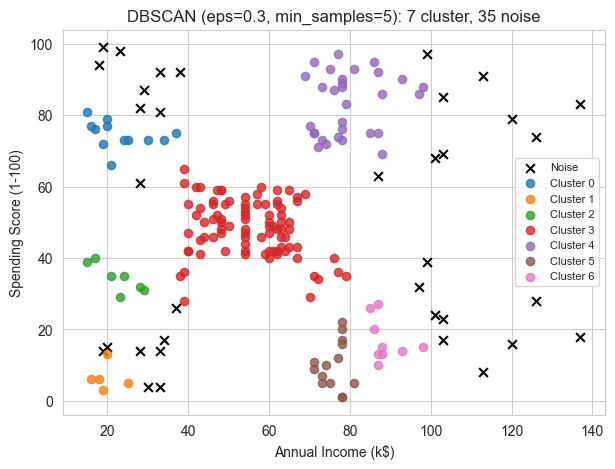

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(ax, X, labels_dbscan, f"DBSCAN (eps=0.3, min_samples=5): {n_clusters_db} cluster, {n_noise_db} noise")
plt.show()

,eps,min_samples,n_cluster,n_noise,noise_%,silhouette
0,0.2,3,13,44,22.0,0.4697
1,0.2,5,7,77,38.5,0.5856
2,0.2,8,2,116,58.0,0.6027
3,0.2,10,1,129,64.5,NaN
4,0.3,3,9,14,7.0,0.4720
5,0.3,5,7,35,17.5,0.5243
6,0.3,8,5,72,36.0,0.5926
7,0.3,10,4,88,44.0,0.6073
8,0.4,3,4,10,5.0,0.3954
9,0.4,5,4,15,7.5,0.4781


DBSCAN terpilih: eps=0.4, min_samples=5 | cluster=4, noise=15, silhouette=0.4781


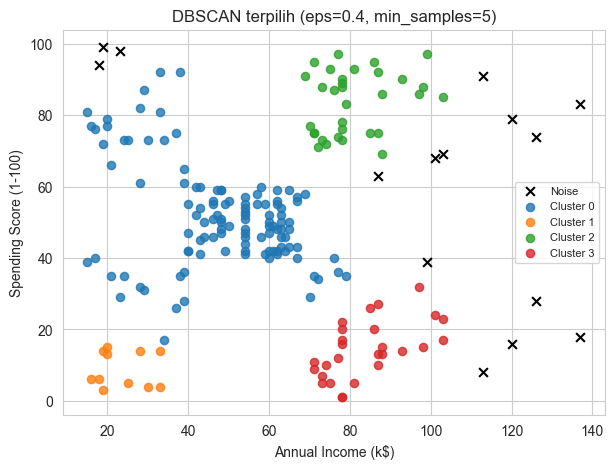

In [11]:
def valid_metric(X_, labels_):
    """Silhouette pada titik non-noise; None jika tidak valid."""
    labels_ = np.asarray(labels_)
    m = labels_ != -1
    k = len(set(labels_[m]))
    if k < 2 or k >= m.sum():
        return None
    return silhouette_score(np.asarray(X_)[m], labels_[m])

rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [3, 5, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_c = len(set(lab)) - (1 if -1 in lab else 0)
        n_n = int((lab == -1).sum())
        rows.append({
            "eps": eps, "min_samples": ms, "n_cluster": n_c, "n_noise": n_n,
            "noise_%": round(n_n / len(lab) * 100, 1),
            "silhouette": valid_metric(X_scaled, lab),
        })
grid_db = pd.DataFrame(rows)
display(grid_db.round(4))

# Pilih kombinasi: 3-8 cluster, noise <= 10%, silhouette (non-noise) tertinggi
cand = grid_db[grid_db["n_cluster"].between(3, 8) & (grid_db["noise_%"] <= 10) & grid_db["silhouette"].notna()]
if cand.empty:
    cand = grid_db[grid_db["silhouette"].notna()]
best_row = cand.sort_values("silhouette", ascending=False).iloc[0]
EPS_BEST, MS_BEST = float(best_row["eps"]), int(best_row["min_samples"])
labels_dbscan_best = DBSCAN(eps=EPS_BEST, min_samples=MS_BEST).fit_predict(X_scaled)
print(f"DBSCAN terpilih: eps={EPS_BEST}, min_samples={MS_BEST} | cluster={int(best_row['n_cluster'])}, noise={int(best_row['n_noise'])}, silhouette={best_row['silhouette']:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(ax, X, labels_dbscan_best, f"DBSCAN terpilih (eps={EPS_BEST}, min_samples={MS_BEST})")
plt.show()

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?


---

Jawaban:

- Pengaruh eps: Semakin besar eps, semakin banyak titik yang saling dianggap bertetangga, sehingga noise berkurang dan cluster-cluster yang berdekatan mulai menyatu. eps yang terlalu kecil membuat banyak titik gagal menjadi core point sehingga noise membengkak dan cluster terpecah-pecah; eps yang terlalu besar menggabungkan beberapa kelompok menjadi satu cluster besar.
- Pengaruh min_samples: Semakin besar min_samples, syarat kepadatan menjadi lebih ketat. Akibatnya lebih banyak titik di tepi kelompok menjadi noise dan cluster kecil dapat hilang seluruhnya. Nilai yang kecil membuat DBSCAN lebih longgar dan lebih mudah menghubungkan titik-titik yang renggang.
- Kombinasi bermasalah: Pada tabel terlihat kombinasi eps kecil dengan min_samples besar menghasilkan noise yang sangat banyak, sedangkan eps besar dengan min_samples kecil menghasilkan satu atau dua cluster besar. Kombinasi seperti itu tidak dipilih meskipun silhouette-nya kadang terlihat tinggi, karena kualitas segmentasinya tidak berguna. Kombinasi yang dipilih adalah yang menghasilkan beberapa cluster dengan noise rendah dan silhouette terbaik.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)
print("Jumlah subcluster di pohon CF:", len(birch.subcluster_centers_))

Jumlah subcluster di pohon CF: 10


In [13]:
display(pd.Series(labels_birch).value_counts().sort_index().to_frame("jumlah_anggota").rename_axis("cluster"))
print("Jumlah cluster BIRCH:", len(set(labels_birch)))

,jumlah_anggota
cluster,
0,36
1,109
2,8
3,25
4,22


Jumlah cluster BIRCH: 5


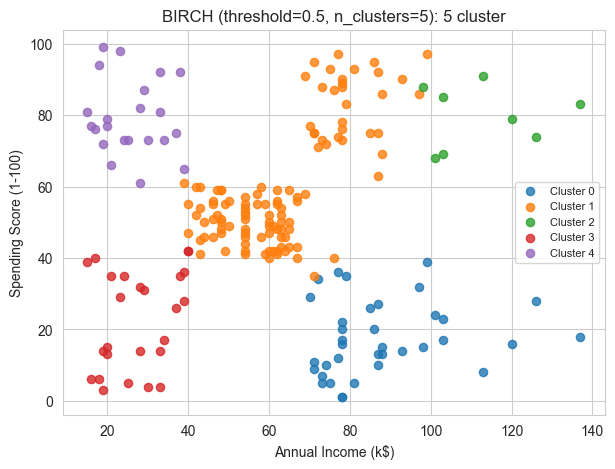

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(ax, X, labels_birch, f"BIRCH (threshold=0.5, n_clusters=5): {len(set(labels_birch))} cluster")
plt.show()

In [15]:
rows = []
for t in [0.3, 0.5, 0.7, 1.0]:
    b = Birch(threshold=t, n_clusters=5).fit(X_scaled)
    lab = b.labels_
    rows.append({
        "threshold": t,
        "n_subcluster": len(b.subcluster_centers_),
        "n_cluster_akhir": len(set(lab)),
        "silhouette": silhouette_score(X_scaled, lab) if len(set(lab)) > 1 else None,
    })
tbl_birch_t = pd.DataFrame(rows)
print("Pengaruh threshold (n_clusters=5):")
display(tbl_birch_t.round(4))

rows = []
for nc in [None, 3, 5, 7]:
    b = Birch(threshold=0.5, n_clusters=nc).fit(X_scaled)
    lab = b.labels_
    rows.append({
        "n_clusters": nc if nc is not None else "None",
        "n_subcluster": len(b.subcluster_centers_),
        "n_cluster_akhir": len(set(lab)),
        "silhouette": silhouette_score(X_scaled, lab) if len(set(lab)) > 1 else None,
    })
print("\nPengaruh n_clusters (threshold=0.5):")
display(pd.DataFrame(rows).round(4))

Pengaruh threshold (n_clusters=5):


c:\Users\Lazzain\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,threshold,n_subcluster,n_cluster_akhir,silhouette
0,0.3,23,5,0.4781
1,0.5,10,5,0.4145
2,0.7,6,5,0.4207
3,1.0,4,4,0.3886



Pengaruh n_clusters (threshold=0.5):


,n_clusters,n_subcluster,n_cluster_akhir,silhouette
0,None,10,10,0.4774
1,3,10,3,0.3382
2,5,10,5,0.4145
3,7,10,7,0.5217


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?


---

Jawaban:

- Pengaruh threshold: Ketika threshold diperbesar, radius maksimum tiap subcluster bertambah sehingga lebih banyak titik terserap ke subcluster yang sama dan jumlah subcluster menurun. Jika n_clusters ditentukan, subcluster tersebut kemudian digabung lagi hingga jumlah cluster akhir sesuai target, sehingga pengaruh threshold pada jumlah cluster akhir kecil dan lebih tampak pada bentuk batas antar cluster.
- BIRCH vs DBSCAN pada titik yang jauh dari kelompok utama: DBSCAN menandai titik yang tidak memenuhi syarat kepadatan sebagai noise (-1) dan tidak memasukkannya ke cluster mana pun. BIRCH tidak mengenal noise: setiap titik pasti masuk ke subcluster terdekat, sehingga titik yang jauh tetap ikut membentuk atau menggeser subcluster dan dapat memengaruhi cluster akhir.
- Pengaruh n_clusters: Ya. Dengan n_clusters=None, jumlah cluster akhir sama dengan jumlah subcluster dan sepenuhnya ditentukan oleh threshold, sehingga dapat sangat banyak. Dengan n_clusters tertentu, tahap global clustering menggabungkan subcluster menjadi jumlah yang diminta, sehingga hasilnya lebih ringkas dan stabil .

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=RANDOM_STATE)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)
print("Konvergen:", gmm.converged_, "| iterasi EM:", gmm.n_iter_)
print("Bobot komponen:", gmm.weights_.round(3))

Konvergen: True | iterasi EM: 5
Bobot komponen: [0.413 0.197 0.104 0.166 0.121]


In [17]:
display(pd.Series(labels_gmm).value_counts().sort_index().to_frame("jumlah_anggota").rename_axis("cluster"))

proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f"P(komp {i})" for i in range(proba.shape[1])]).round(3)
proba_df.insert(0, "label", labels_gmm)
print("Contoh probabilitas keanggotaan:")
display(proba_df.head(8))

max_p = proba.max(axis=1)
print(f"\nTitik dengan probabilitas maksimum < 0.9: {(max_p < 0.9).sum()} dari {len(max_p)}")
print("Lima titik paling tidak pasti:")
idx_unc = np.argsort(max_p)[:5]
display(pd.concat([X.iloc[idx_unc], proba_df.iloc[idx_unc]], axis=1))

,jumlah_anggota
cluster,
0,84
1,39
2,21
3,33
4,23


Contoh probabilitas keanggotaan:


,label,P(komp 0),P(komp 1),P(komp 2),P(komp 3),P(komp 4)
0,4,0.0,0.0,0.001,0.0,0.999
1,2,0.0,0.0,1.000,0.0,0.000
2,4,0.0,0.0,0.000,0.0,1.000
3,2,0.0,0.0,1.000,0.0,0.000
4,4,0.0,0.0,0.002,0.0,0.998
5,2,0.0,0.0,1.000,0.0,0.000
6,4,0.0,0.0,0.000,0.0,1.000
7,2,0.0,0.0,1.000,0.0,0.000



Titik dengan probabilitas maksimum < 0.9: 8 dari 200
Lima titik paling tidak pasti:


,Annual Income (k$),Spending Score (1-100),label,P(komp 0),P(komp 1),P(komp 2),P(komp 3),P(komp 4)
124,70,29,3,0.497,0.0,0.000,0.503,0.000
48,40,42,0,0.611,0.0,0.000,0.000,0.388
49,40,42,0,0.611,0.0,0.000,0.000,0.388
27,28,61,2,0.279,0.0,0.675,0.000,0.046
160,79,35,0,0.772,0.0,0.000,0.228,0.000


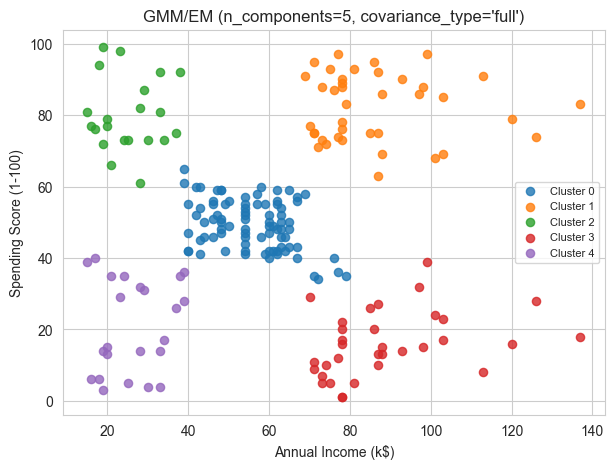

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(ax, X, labels_gmm, "GMM/EM (n_components=5, covariance_type='full')")
plt.show()

,n_components,silhouette,BIC,AIC
0,2,0.3791,1153.9047,1117.6232
1,3,0.4302,1151.7183,1095.6469
2,4,0.4134,1103.7901,1027.9288
3,5,0.5537,1058.6523,963.0010
4,6,0.5170,1074.6828,959.2417
5,7,0.5091,1087.3285,952.0975
6,8,0.4302,1102.3707,947.3498


n_components dengan Silhouette tertinggi: 5
n_components dengan BIC terendah        : 5


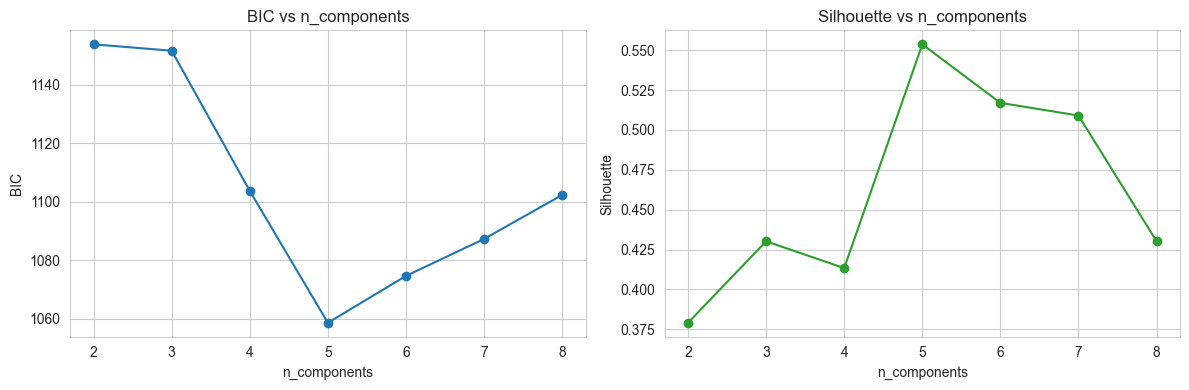

In [19]:
rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=RANDOM_STATE).fit(X_scaled)
    lab = g.predict(X_scaled)
    rows.append({
        "n_components": k,
        "silhouette": silhouette_score(X_scaled, lab),
        "BIC": g.bic(X_scaled),
        "AIC": g.aic(X_scaled),
    })
tbl_gmm = pd.DataFrame(rows)
display(tbl_gmm.round(4))

k_sil = int(tbl_gmm.loc[tbl_gmm["silhouette"].idxmax(), "n_components"])
k_bic = int(tbl_gmm.loc[tbl_gmm["BIC"].idxmin(), "n_components"])
print("n_components dengan Silhouette tertinggi:", k_sil)
print("n_components dengan BIC terendah        :", k_bic)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tbl_gmm["n_components"], tbl_gmm["BIC"], marker="o")
axes[0].set_title("BIC vs n_components"); axes[0].set_xlabel("n_components"); axes[0].set_ylabel("BIC")
axes[1].plot(tbl_gmm["n_components"], tbl_gmm["silhouette"], marker="o", color="tab:green")
axes[1].set_title("Silhouette vs n_components"); axes[1].set_xlabel("n_components"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?


---

Jawaban:

- Probabilitas keanggotaan: predict_proba memberikan peluang sebuah titik berasal dari tiap komponen Gaussian (soft assignment). Sebagian besar titik memiliki probabilitas mendekati 1 pada satu komponen, sedangkan titik yang berada di perbatasan dua kelompok memiliki probabilitas yang terbagi, seperti terlihat pada daftar titik paling tidak pasti. Label cluster diambil dari komponen dengan probabilitas terbesar.
- Pengaruh n_components: Jika jumlah komponen kurang dari struktur sebenarnya, beberapa kelompok digabung dalam satu Gaussian: jika berlebih, satu kelompok dipecah menjadi beberapa komponen kecil. Likelihood terus naik seiring penambahan komponen, sehingga diperlukan kriteria seperti BIC yang memberi penalti pada kompleksitas.
- Mengapa jumlah cluster harus ditentukan di awal: GMM adalah model parametrik dengan jumlah komponen yang tetap: algoritma EM hanya mengestimasi mean, kovarians, dan bobot setiap komponen, bukan jumlah komponennya. Karena itu n_components dipilih lewat perbandingan model (BIC, silhouette, dan visualisasi).
- Silhouette tertinggi vs BIC terendah: Keduanya mengukur hal berbeda. Silhouette menilai keterpisahan dan kekompakan cluster hasil label, sedangkan BIC menilai kecocokan model probabilistik terhadap data dengan penalti jumlah parameter. Karena itu keduanya tidak selalu menunjuk nilai n_components yang sama: bandingkan kedua nilai terbaik pada output di atas.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
def evaluate(X_, labels_, exclude_noise=False):
    """Hitung metrik internal. Untuk DBSCAN, noise dikeluarkan lebih dulu."""
    X_ = np.asarray(X_)
    labels_ = np.asarray(labels_)
    if exclude_noise:
        m = labels_ != -1
        X_, labels_ = X_[m], labels_[m]
    k = len(set(labels_))
    if k < 2 or k >= len(labels_):
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {
        "silhouette": silhouette_score(X_, labels_),
        "davies_bouldin": davies_bouldin_score(X_, labels_),
        "calinski_harabasz": calinski_harabasz_score(X_, labels_),
    }

print(evaluate(X_scaled, labels_gmm))

{'silhouette': 0.5536892843811245, 'davies_bouldin': 0.5760100302410824, 'calinski_harabasz': 244.9401969858632}


In [21]:
def n_clusters_of(lab):
    lab = np.asarray(lab)
    return len(set(lab)) - (1 if -1 in lab else 0)

models = {
    f"DBSCAN (eps={EPS_BEST}, min_samples={MS_BEST})": (labels_dbscan_best, True),
    "BIRCH (threshold=0.5, n_clusters=5)": (labels_birch, False),
    "GMM/EM (n_components=5, full)": (labels_gmm, False),
}
rows = []
for name, (lab, excl) in models.items():
    r = evaluate(X_scaled, lab, exclude_noise=excl)
    rows.append({
        "model": name,
        "jumlah_cluster": n_clusters_of(lab),
        "jumlah_noise": int((np.asarray(lab) == -1).sum()) if excl else "N/A",
        "silhouette": r["silhouette"],
        "davies_bouldin": r["davies_bouldin"],
        "calinski_harabasz": r["calinski_harabasz"],
    })
summary = pd.DataFrame(rows)
display(summary.round(4))

,model,jumlah_cluster,jumlah_noise,silhouette,davies_bouldin,calinski_harabasz
0,"DBSCAN (eps=0.4, min_samples=5)",4,15,0.4781,0.5912,146.8880
1,"BIRCH (threshold=0.5, n_clusters=5)",5,N/A,0.4145,0.6979,125.9486
2,"GMM/EM (n_components=5, full)",5,N/A,0.5537,0.5760,244.9402


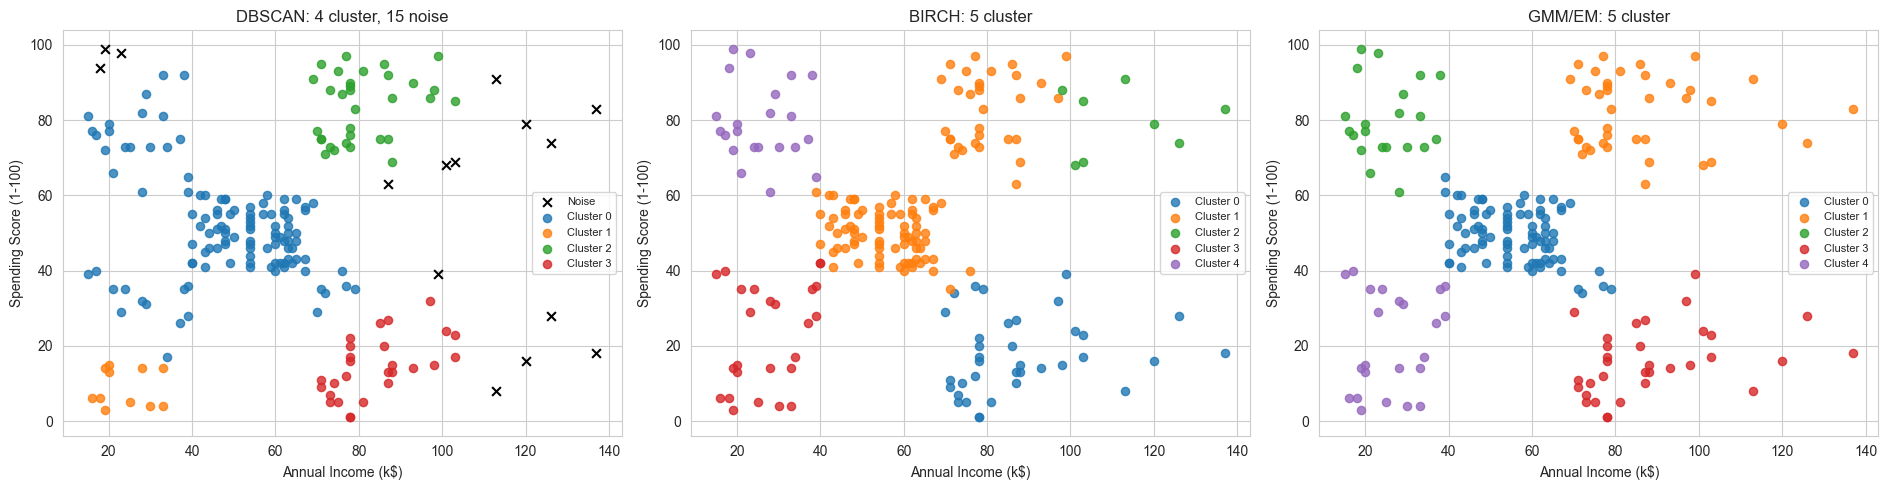

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
plot_clusters(axes[0], X, labels_dbscan_best,
              f"DBSCAN: {n_clusters_of(labels_dbscan_best)} cluster, {int((labels_dbscan_best == -1).sum())} noise")
plot_clusters(axes[1], X, labels_birch, f"BIRCH: {n_clusters_of(labels_birch)} cluster")
plot_clusters(axes[2], X, labels_gmm, f"GMM/EM: {n_clusters_of(labels_gmm)} cluster")
plt.tight_layout()
plt.show()

In [23]:
def profile(labels_, name):
    d = X.copy()
    d["cluster"] = np.asarray(labels_)
    g = d.groupby("cluster")
    out = pd.DataFrame({
        "n_anggota": g.size(),
        "income_median": g[INC].median(),
        "income_mean": g[INC].mean(),
        "spending_median": g[SPD].median(),
        "spending_mean": g[SPD].mean(),
    }).round(2)
    print(f"=== Profil cluster: {name} ===")
    display(out)
    return out

prof_db = profile(labels_dbscan_best, f"DBSCAN (label -1 = noise)")
prof_birch = profile(labels_birch, "BIRCH")
prof_gmm = profile(labels_gmm, "GMM/EM")

# Interpretasi tambahan (Gender tidak dipakai sebagai input model)
gender_tbl = pd.crosstab(labels_gmm, df["Gender"], normalize="index").mul(100).round(1)
print("Komposisi Gender per cluster GMM (%):")
display(gender_tbl)

=== Profil cluster: DBSCAN (label -1 = noise) ===


,n_anggota,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
-1,15,113.0,96.13,69.0,61.80
0,115,49.0,48.30,50.0,51.73
1,11,20.0,23.73,6.0,8.91
2,32,78.0,80.88,86.0,83.62
3,27,81.0,83.93,14.0,14.44


=== Profil cluster: BIRCH ===


,n_anggota,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
0,36,83.0,87.75,16.0,17.58
1,109,62.0,62.39,55.0,59.26
2,8,108.0,112.62,81.0,79.62
3,25,28.0,27.40,26.0,22.60
4,22,24.5,25.73,77.0,79.36


=== Profil cluster: GMM/EM ===


,n_anggota,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
0,84,55.5,55.64,49.5,49.37
1,39,79.0,86.54,83.0,82.13
2,21,24.0,25.10,77.0,80.05
3,33,86.0,88.82,15.0,16.00
4,23,25.0,26.30,17.0,20.91


Komposisi Gender per cluster GMM (%):


Gender,Female,Male
row_0,,
0,59.5,40.5
1,53.8,46.2
2,57.1,42.9
3,45.5,54.5
4,60.9,39.1


### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak. Jumlah cluster muncul dari eps dan min_samples | Opsional. Bisa diberikan lewat n_clusters, atau None sehingga ditentukan threshold | Ya, lewat n_components |
| Dapat memberi label noise secara eksplisit? | Ya (label -1) | Tidak | Tidak secara eksplisit; titik dengan probabilitas maksimum rendah menandakan keanggotaan yang tidak pasti |
| Parameter yang paling memengaruhi hasil | eps dan min_samples | threshold dan n_clusters (juga branching_factor) | n_components dan covariance_type |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas, selama kepadatannya cukup | Cenderung bulat/kompak karena subcluster berbasis radius | Elips (Gaussian), bentuk bergantung pada covariance_type |
| Kelebihan | Mendeteksi noise, tidak perlu menentukan k, bisa menemukan bentuk tidak beraturan | Cepat dan hemat memori, cocok untuk data besar dan dapat diproses bertahap | Memberi probabilitas keanggotaan (soft clustering), mampu memodelkan cluster elips dengan ukuran berbeda, ada kriteria BIC/AIC untuk memilih model |
| Kekurangan | Sensitif terhadap eps dan min_samples, kesulitan jika kepadatan antar cluster berbeda | Tidak ada noise, hasil dipengaruhi urutan data dan threshold, kurang cocok untuk cluster non-bulat | Perlu menentukan jumlah komponen, bergantung pada asumsi Gaussian dan inisialisasi (bisa terjebak optimum lokal) |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter threshold dan n_clusters memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?


---

### Jawaban

1. Mengapa scaling diperlukan. DBSCAN dan BIRCH memakai jarak Euclidean sehingga fitur dengan skala besar mendominasi, dan GMM menghitung kovarians yang sensitif terhadap skala. Walaupun rentang Annual Income dan Spending Score pada dataset ini tidak berbeda jauh, StandardScaler membuat keduanya berkontribusi setara dan membuat eps serta threshold bermakna dalam satuan simpangan baku.

2. Pengaruh parameter DBSCAN. Pada tabel percobaan terlihat bahwa menaikkan eps menurunkan jumlah noise dan menggabungkan cluster yang berdekatan, sedangkan menaikkan min_samples memperketat syarat kepadatan sehingga noise bertambah dan cluster kecil hilang. Kombinasi eps kecil dengan min_samples besar menghasilkan terlalu banyak noise, sedangkan eps besar dengan min_samples kecil menghasilkan satu cluster besar. Parameter yang dipilih adalah yang memberi beberapa cluster dengan noise rendah dan silhouette terbaik.

3. Pengaruh threshold dan n_clusters pada BIRCH. threshold yang lebih besar menghasilkan subcluster yang lebih sedikit dan lebih lebar. n_clusters menentukan jumlah cluster akhir karena subcluster digabung lagi sampai sesuai target; tanpa n_clusters jumlah cluster akhir sama dengan jumlah subcluster dan sangat bergantung pada threshold.

4. Probabilitas keanggotaan GMM dan EM. Probabilitas keanggotaan (responsibility) adalah peluang posterior sebuah titik berasal dari suatu komponen Gaussian. Pada E-step, EM menghitung responsibility ini berdasarkan parameter saat ini; pada M-step, mean, kovarians, dan bobot komponen diperbarui dengan memakai responsibility sebagai bobot. Kedua langkah diulang sampai log-likelihood konvergen.

5. Model yang paling mudah diinterpretasikan. Kelompok pelanggan pada dataset ini berbentuk gumpalan yang relatif bulat dan terpisah, sehingga BIRCH dan GMM dengan lima cluster menghasilkan segmentasi yang mudah dibaca dan semua pelanggan mendapat label. GMM memberi tambahan informasi berupa probabilitas keanggotaan. DBSCAN juga mudah dibaca bila parameternya tepat, tetapi sebagian pelanggan berstatus noise sehingga tidak masuk segmen mana pun.

6. Konsistensi metrik evaluasi. Metrik tidak selalu menunjuk algoritma terbaik yang sama. Silhouette, Davies-Bouldin, dan Calinski-Harabasz menyukai cluster yang kompak dan terpisah jelas, sehingga cenderung menguntungkan hasil yang berbentuk bulat. Metrik DBSCAN dihitung tanpa titik noise sehingga tidak sepenuhnya sebanding dengan BIRCH dan GMM yang mengevaluasi seluruh data. Selain itu, tiap metrik menekankan aspek berbeda (jarak ke centroid, rasio sebaran antar dan dalam cluster), sehingga peringkat model bisa berbeda.

7. Karakteristik cluster. Berdasarkan median pendapatan dan spending score pada tabel profil, pelanggan terbagi menjadi lima segmen yang konsisten pada BIRCH dan GMM:
- Pendapatan rendah, spending rendah: pelanggan hemat.
- Pendapatan rendah, spending tinggi: pelanggan impulsif/boros relatif terhadap pendapatannya.
- Pendapatan sedang, spending sedang: pelanggan standar (segmen terbesar).
- Pendapatan tinggi, spending tinggi: pelanggan prioritas, target utama promosi.
- Pendapatan tinggi, spending rendah: pelanggan potensial yang belum banyak berbelanja.

Penomoran label berbeda antar algoritma, sehingga pencocokan dilakukan berdasarkan nilai median pada tabel profil.

8. Keterbatasan. Hanya dua fitur yang dipakai sehingga informasi lain seperti usia dan gender tidak ikut membentuk segmen, padahal dapat mengubah profil pelanggan. Dataset hanya 200 baris sehingga hasil, terutama DBSCAN dan estimasi kovarians GMM, mudah berubah mengikuti pemilihan parameter. Tidak ada label asli, sehingga evaluasi hanya mengandalkan metrik internal dan interpretasi visual.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.


---

### Kesimpulan

1. Data pelanggan mal membentuk sekitar lima segmen yang terlihat jelas pada ruang Annual Income dan Spending Score. BIRCH dan GMM dengan lima cluster memberikan hasil yang paling mudah diinterpretasikan karena seluruh pelanggan memperoleh label dan segmennya bermakna secara bisnis.
2. DBSCAN dapat menemukan kelompok padat dan menandai titik yang tidak masuk kelompok sebagai noise, tetapi hasilnya sangat bergantung pada eps dan min_samples. Pada eksperimen ini parameter dipilih lewat grid dengan kriteria jumlah cluster 3 sampai 8, noise tidak lebih dari 10%, dan silhouette tertinggi.
3. BIRCH menggunakan threshold=0.5 dan n_clusters=5; GMM menggunakan n_components=5 dengan covariance_type='full', dengan lima komponen dipertimbangkan bersama nilai BIC dan silhouette serta visualisasi.
4. Perbedaan utama: DBSCAN berbasis kepadatan dan memiliki noise, BIRCH merangkum data dalam pohon subcluster sehingga efisien, sedangkan GMM berbasis model probabilistik dan memberi probabilitas keanggotaan.
5. Hasil eksperimen menunjukkan bahwa tidak ada satu metrik yang cukup untuk memilih algoritma terbaik, sehingga metrik perlu dibaca bersama visualisasi dan konteks bisnis.

### Saran

- Tambahkan fitur lain seperti usia dan gender (dengan encoding) untuk segmentasi yang lebih kaya.
- Bandingkan dengan K-Means dan Hierarchical Clustering sebagai pembanding.
- Coba variasi covariance_type (tied, diag, spherical) pada GMM dan variasi branching_factor pada BIRCH.
- Gunakan pendekatan pemilihan eps yang lebih sistematis, misalnya k-distance plot, serta uji kestabilan hasil dengan beberapa random_state atau sampel ulang.
- Lakukan validasi segmen dengan pihak bisnis, misalnya dengan menguji strategi promosi berbeda pada tiap segmen.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)